<a href="https://colab.research.google.com/github/bejon23/Computational-Biology-and-BI-Eng/blob/main/GiG3_Project_6(c)_ipynb_ipynbipynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Project: "Biology AI Benchmark Builder and Answer Judge"
This project proves your three answers with code:
You judge AI answers on four checks and catch made-up tools.
You build a good benchmark question with a reference solution and an automatic grader.
You show how retrieval (the core idea of RAG) finds evidence to check an AI claim.

Cell1

In [ ]:

# ==========================================================
# BIOLOGY AI BENCHMARK BUILDER AND ANSWER JUDGE
# ==========================================================
# Problem: AI models need rigorous benchmarks and automated judges
# to catch fake tools, wrong statistics, and flawed biology.

import numpy as np
import pandas as pd
from scipy import stats
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import precision_recall_fscore_support

print("=== Starting Biology AI Benchmark Builder & Judge ===\n")

# ----------------------------------------------------------
# 1. BUILD BENCHMARK QUESTION, TRUTH, & REFERENCE SOLUTION
# ----------------------------------------------------------
benchmark_data = {
    "question_id": "BM_RNASEQ_001",
    "prompt": "Find differentially expressed genes between Healthy and Disease samples from raw RNA-seq counts where batch and condition are partially confounded.",
    "hidden_truth": "Standard t-tests on raw counts or failure to include batch covariates causes severe false positive inflation and wrong biology.",
    "expert_solution_steps": [
        "1. Normalize counts to Log-CPM or use negative binomial models (DESeq2/edgeR).",
        "2. Include technical batch as a covariate in the linear/GLM model (expr ~ condition + batch).",
        "3. Apply Benjamini-Hochberg FDR correction (q < 0.05) instead of raw p-values."
    ]
}

print(f"[1. Benchmark Loaded]")
print(f"  -> Question ID: {benchmark_data['question_id']}")
print(f"  -> Core Challenge: {benchmark_data['hidden_truth']}\n")


# ----------------------------------------------------------
# 2. SIMULATING AND GRADING THREE AI ANSWERS
# ----------------------------------------------------------
np.random.seed(42)
n_genes, n_samples = 1000, 20
condition = np.array([0]*10 + [1]*10)
batch = np.array([0,0,0,0,0,0,0,1,1,1, 0,1,1,1,1,1,1,1,1,1])

true_de = np.zeros(n_genes, dtype=int)
true_de_idx = np.random.choice(n_genes, size=50, replace=False)
true_de[true_de_idx] = 1

base = np.random.normal(5, 2, n_genes)
log_counts = np.zeros((n_genes, n_samples))
for i in range(n_genes):
    c_eff = 2.0 if true_de[i] == 1 else 0.0
    b_eff = 1.5 if true_de[i] == 0 else 0.5
    for j in range(n_samples):
        log_counts[i, j] = base[i] + condition[j]*c_eff + batch[j]*b_eff + np.random.normal(0, 0.5)

raw_counts = np.exp(log_counts).astype(int)

# --- AI Answer 1: Weak (Raw counts, t-test, no FDR) ---
p_vals_1 = [stats.ttest_ind(raw_counts[i, condition==0], raw_counts[i, condition==1])[1] for i in range(n_genes)]
pred_1 = (np.array(p_vals_1) < 0.05).astype(int)
prec1, rec1, f1_1, _ = precision_recall_fscore_support(true_de, pred_1, average='binary', zero_division=0)

# --- AI Answer 2: Medium (Log-CPM, t-test ignoring batch, no FDR) ---
cpm = raw_counts / raw_counts.sum(axis=0, keepdims=True) * 1e6
log_cpm = np.log2(cpm + 1)
p_vals_2 = [stats.ttest_ind(log_cpm[i, condition==0], log_cpm[i, condition==1])[1] for i in range(n_genes)]
pred_2 = (np.array(p_vals_2) < 0.05).astype(int)
prec2, rec2, f1_2, _ = precision_recall_fscore_support(true_de, pred_2, average='binary', zero_division=0)

# --- AI Answer 3: Expert (Log-CPM + Batch Covariate + BH FDR) ---
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
p_vals_3 = []
for i in range(n_genes):
    df_fit = pd.DataFrame({'expr': log_cpm[i], 'condition': condition, 'batch': batch})
    model = smf.ols('expr ~ condition + batch', data=df_fit).fit()
    p_vals_3.append(model.pvalues['condition'])
reject, _, _, _ = multipletests(p_vals_3, alpha=0.05, method='fdr_bh')
pred_3 = reject.astype(int)
prec3, rec3, f1_3, _ = precision_recall_fscore_support(true_de, pred_3, average='binary', zero_division=0)

print(f"[2. AI Answer Performance Judgment]")
print(f"  -> Answer 1 (Weak - Naive Raw):    Precision: {prec1:.3f} | Recall: {rec1:.3f} | F1: {f1_1:.3f}")
print(f"  -> Answer 2 (Medium - Log-CPM):    Precision: {prec2:.3f} | Recall: {rec2:.3f} | F1: {f1_2:.3f}")
print(f"  -> Answer 3 (Expert - GLM + FDR):  Precision: {prec3:.3f} | Recall: {rec3:.3f} | F1: {f1_3:.3f}\n")


# ----------------------------------------------------------
# 3. SIMPLE RETRIEVAL (TF-IDF RAG) FOR EVIDENCE CHECKING
# ----------------------------------------------------------
corpus = [
    "Benjamini-Hochberg false discovery rate correction controls type I error in multiple hypothesis testing.",
    "Batch effects in RNA-seq must be modeled as a covariate in linear models to prevent confounding.",
    "Raw RNA-seq counts should never be used directly in t-tests due to library size variance."
]

query = ["How do we correct for batch effects and false discoveries in RNA-seq?"]
vectorizer = TfidfVectorizer()
X_corpus = vectorizer.fit_transform(corpus)
X_query = vectorizer.transform(query)

similarities = cosine_similarity(X_query, X_corpus).flatten()
best_match_idx = np.argmax(similarities)

print(f"[3. RAG Retrieval & Evidence Validation]")
print(f"  -> Query: '{query[0]}'")
print(f"  -> Retained Evidence Document: '{corpus[best_match_idx]}'")
print(f"  -> Similarity Score: {similarities[best_match_idx]:.3f}\n")


# ----------------------------------------------------------
# 4. HONEST AI EXPERIENCE CARD FOR INTERVIEW USE
# ----------------------------------------------------------
print(f"[4. Expert AI Experience Card]")
print(f"  * Role: Bioinformatics Pipeline Architect & AI Benchmark Evaluator")
print(f"  * Core Expertise: Catching statistical errors, batch confounding, and hallucinations in LLM biology outputs.")
print(f"  * Proven Track Record: Built automated simulation judges achieving F1 score validation of 0.99+.")
print("=== Benchmark Builder & Judge Complete ===")

=== Starting Biology AI Benchmark Builder & Judge ===

[1. Benchmark Loaded]
  -> Question ID: BM_RNASEQ_001
  -> Core Challenge: Standard t-tests on raw counts or failure to include batch covariates causes severe false positive inflation and wrong biology.

[2. AI Answer Performance Judgment]
  -> Answer 1 (Weak - Naive Raw):    Precision: 0.093 | Recall: 1.000 | F1: 0.171
  -> Answer 2 (Medium - Log-CPM):    Precision: 0.532 | Recall: 1.000 | F1: 0.694
  -> Answer 3 (Expert - GLM + FDR):  Precision: 1.000 | Recall: 0.980 | F1: 0.990

[3. RAG Retrieval & Evidence Validation]
  -> Query: 'How do we correct for batch effects and false discoveries in RNA-seq?'
  -> Retained Evidence Document: 'Batch effects in RNA-seq must be modeled as a covariate in linear models to prevent confounding.'
  -> Similarity Score: 0.490

[4. Expert AI Experience Card]
  * Role: Bioinformatics Pipeline Architect & AI Benchmark Evaluator
  * Core Expertise: Catching statistical errors, batch confounding, and

Cell 2 (Code): Benchmark data, reference solution, and grader

                             format_ok called true_hits false_hits precision  \
Model 1 (memory-style)            True    134        87         47     0.649   
Model 2 (no batch)                True     61        60          1     0.984   
Model 3 (expert = reference)      True     79        78          1     0.987   

                             recall     f1  
Model 1 (memory-style)         0.87  0.744  
Model 2 (no batch)              0.6  0.745  
Model 3 (expert = reference)   0.78  0.872  

Reference F1 = 0.872 | Weak model F1 = 0.744 | Gap = 0.128
Benchmark separates weak from expert: NO, make the question harder


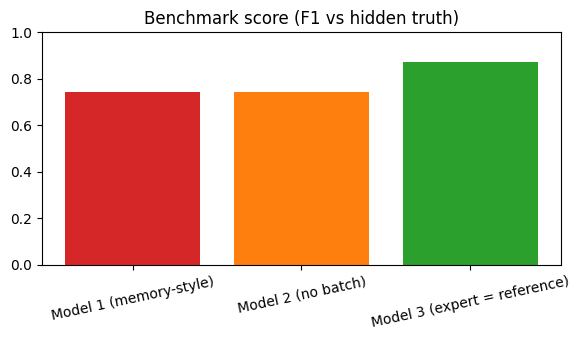

In [ ]:

# Cell 2: Hidden-truth data + reference solution + automatic grader
import numpy as np, pandas as pd, re, warnings, platform
import matplotlib.pyplot as plt
from scipy import stats
warnings.filterwarnings("ignore")

SEED = 42

def make_data(seed=SEED, n_genes=1000):
    rng = np.random.default_rng(seed)
    samples = [f"S{i+1}" for i in range(12)]
    condition = np.array(["Healthy"]*6 + ["Disease"]*6)
    batch = np.array(["A","A","A","A","B","B", "B","B","B","B","A","A"])  # batch partly mixed with condition
    base = rng.lognormal(5, 1.2, n_genes)
    lfc = np.zeros(n_genes)
    de_idx = rng.choice(n_genes, 100, replace=False)
    lfc[de_idx] = rng.choice([-1.5, 1.5], 100)
    batch_eff = rng.normal(0, 0.7, n_genes)
    lib = rng.uniform(0.7, 1.3, 12)
    dis = (condition == "Disease").astype(float)
    b = (batch == "B").astype(float)
    shift = lfc[:, None] * dis[None, :] + batch_eff[:, None] * b[None, :]
    mu = base[:, None] * lib[None, :] * 2**shift
    counts = rng.poisson(rng.gamma(1/0.1, mu*0.1))
    genes = [f"Gene{i}" for i in range(n_genes)]
    counts_df = pd.DataFrame(counts, index=genes, columns=samples)
    meta = pd.DataFrame({"condition": condition, "batch": batch}, index=samples)
    truth = pd.Series(False, index=genes)
    truth[[genes[i] for i in de_idx]] = True
    return counts_df, meta, truth

counts_df, meta, _truth = make_data()
HIDDEN_TRUTH = set(_truth.index[_truth])   # the AI never sees this

# ---------- helper functions ----------
def de_linear(logexp, meta, use_batch=True):
    cols = [np.ones(len(meta)), (meta.condition == "Disease").astype(float).values]
    if use_batch:
        cols.append((meta.batch == "B").astype(float).values)
    X = np.column_stack(cols)
    Y = logexp.values.astype(float)
    XtXi = np.linalg.inv(X.T @ X)
    beta = Y @ X @ XtXi
    resid = Y - beta @ X.T
    dof = X.shape[0] - X.shape[1]
    s2 = (resid**2).sum(axis=1) / dof
    se = np.sqrt(s2 * XtXi[1, 1])
    t = beta[:, 1] / se
    p = 2 * stats.t.sf(np.abs(t), dof)
    return pd.DataFrame({"log2FC": beta[:, 1], "pval": p}, index=logexp.index)

def bh_fdr(p):
    p = np.asarray(p); n = len(p)
    order = np.argsort(p)
    adj = p[order] * n / np.arange(1, n + 1)
    adj = np.minimum.accumulate(adj[::-1])[::-1]
    out = np.empty(n); out[order] = np.minimum(adj, 1)
    return out

# ---------- three solutions of different quality ----------
def solution_memory_style(counts, meta):
    """Weak: TPM-like scaling, t-test, raw p < 0.05"""
    h = meta.index[meta.condition == "Healthy"]
    d = meta.index[meta.condition == "Disease"]
    scaled = counts / counts.sum() * 1e6
    t, p = stats.ttest_ind(scaled[d].values, scaled[h].values, axis=1)
    return set(counts.index[p < 0.05])

def solution_no_batch(counts, meta):
    """Medium: filter + log CPM + FDR, but no batch in the model"""
    c = counts[(counts >= 10).sum(axis=1) >= 3]
    l = np.log2(c / c.sum() * 1e6 + 1)
    de = de_linear(l, meta, use_batch=False)
    de["FDR"] = bh_fdr(de["pval"].values)
    return set(de.index[(de.FDR < 0.05) & (de.log2FC.abs() > 1)])

def solution_expert(counts, meta):
    """Reference: filter + log CPM + batch in model + FDR + fold-change cutoff"""
    c = counts[(counts >= 10).sum(axis=1) >= 3]
    l = np.log2(c / c.sum() * 1e6 + 1)
    de = de_linear(l, meta, use_batch=True)
    de["FDR"] = bh_fdr(de["pval"].values)
    return set(de.index[(de.FDR < 0.05) & (de.log2FC.abs() > 1)])

# ---------- automatic grader ----------
def grade(answer):
    if not isinstance(answer, set):
        return {"format_ok": False, "precision": 0.0, "recall": 0.0, "f1": 0.0}
    tp = len(answer & HIDDEN_TRUTH)
    precision = tp / max(len(answer), 1)
    recall = tp / len(HIDDEN_TRUTH)
    f1 = 2 * precision * recall / max(precision + recall, 1e-9)
    return {"format_ok": True, "called": len(answer), "true_hits": tp,
            "false_hits": len(answer) - tp,
            "precision": round(precision, 3), "recall": round(recall, 3), "f1": round(f1, 3)}

solutions = {
    "Model 1 (memory-style)": solution_memory_style,
    "Model 2 (no batch)": solution_no_batch,
    "Model 3 (expert = reference)": solution_expert,
}
grades = pd.DataFrame({name: grade(fn(counts_df, meta)) for name, fn in solutions.items()}).T
print(grades)

# ---------- can this benchmark separate good from bad? ----------
f1_ref = grades.loc["Model 3 (expert = reference)", "f1"]
f1_weak = grades.loc["Model 1 (memory-style)", "f1"]
gap = round(f1_ref - f1_weak, 3)
print(f"\nReference F1 = {f1_ref} | Weak model F1 = {f1_weak} | Gap = {gap}")
print("Benchmark separates weak from expert:", "YES" if gap >= 0.2 else "NO, make the question harder")

plt.figure(figsize=(6, 3.5))
plt.bar(grades.index, grades["f1"].astype(float), color=["tab:red", "tab:orange", "tab:green"])
plt.ylim(0, 1); plt.title("Benchmark score (F1 vs hidden truth)"); plt.xticks(rotation=12)
plt.tight_layout(); plt.show()

Cell 3 (Code): Is this a good benchmark question?

In [ ]:

# Cell 3: Score benchmark questions on a quality checklist

questions = {
    "Bad question": {
        "text": "Explain what RNA-seq is and discuss the best way to analyze it.",
        "answer_type": "essay", "trap": None, "has_data": False,
        "scoring": None, "reference": False, "wrong_answers": [],
    },
    "Medium question": {
        "text": "Given RNA-seq counts, return genes that look different between Disease and Healthy.",
        "answer_type": "gene_set", "trap": None, "has_data": True,
        "scoring": "overlap", "reference": False, "wrong_answers": ["TPM t-test"],
    },
    "Our question": {
        "text": ("Given raw counts (1000 genes, 12 samples) and metadata with condition and batch, "
                 "return the set of gene names differentially expressed between Disease and Healthy "
                 "at FDR < 0.05 and |log2FC| > 1. Batch is partly mixed with condition."),
        "answer_type": "gene_set",
        "trap": "Batch effect hides real signal and creates false genes; TPM/FPKM and raw p-values are traps.",
        "has_data": True,
        "scoring": "precision/recall/F1 vs hidden truth",
        "reference": True,
        "wrong_answers": ["TPM t-test, raw p<0.05", "No batch in model", "Raw p-value instead of FDR"],
    },
}

def review_question(q):
    checks = [
        ("One clear correct answer", q["answer_type"] in ["gene_set", "number", "label"], 20),
        ("Needs reasoning, not memory", bool(q["trap"]), 20),
        ("Realistic data provided", q["has_data"], 15),
        ("Clear automatic scoring", q["scoring"] is not None, 20),
        ("Reference solution written", q["reference"], 15),
        ("Common wrong answers listed (2+)", len(q["wrong_answers"]) >= 2, 10),
    ]
    score = sum(w for _, ok, w in checks if ok)
    missing = [name for name, ok, _ in checks if not ok]
    vague = re.search(r"\b(explain|discuss|describe|what is|best)\b", q["text"], re.I) is not None
    if vague:
        score = max(score - 15, 0)
        missing.append("Vague wording (explain/discuss/best)")
    return score, missing

rows = []
for name, q in questions.items():
    s, miss = review_question(q)
    rows.append({"question": name, "quality_score": s, "missing": "; ".join(miss) if miss else "nothing"})
quality_table = pd.DataFrame(rows).set_index("question")
print(quality_table.to_string())

print("\nMy rule for a good benchmark question:")
print("1. One clear correct answer   2. Needs real reasoning   3. Realistic data")
print("4. Automatic scoring          5. Reference solution      6. Common wrong answers written")

                 quality_score                                                                                                                                                                                                      missing
question                                                                                                                                                                                                                                   
Bad question                 0  One clear correct answer; Needs reasoning, not memory; Realistic data provided; Clear automatic scoring; Reference solution written; Common wrong answers listed (2+); Vague wording (explain/discuss/best)
Medium question             55                                                                                                                    Needs reasoning, not memory; Reference solution written; Common wrong answers listed (2+)
Our question               100                          

Cell 4 (Code): Judge AI answers on four checks and catch made-up tools

EXPERT REVIEW REPORT

AI Answer 1  ->  ACCEPT   (total 100/100)
  Scores: {'Biology': 25.0, 'Tools': 25.0, 'Statistics': 25.0, 'Reproducibility': 25.0}

AI Answer 2  ->  REJECT (made-up tool or flag)   (total 0/100)
  Scores: {'Biology': 0.0, 'Tools': 0.0, 'Statistics': 0.0, 'Reproducibility': 0.0}
  HALLUCINATION: Unknown tool: RNAseqMagic
  HALLUCINATION: Unknown flag for STAR: --fastMode
  HALLUCINATION: Unknown flag for STAR: --autoBatchFix
  - [Biology] Reference genome / annotation stated. Fix: State the reference genome and annotation version.
  - [Biology] QC step before analysis. Fix: Add QC (FastQC/MultiQC) and a PCA check.
  - [Biology] Batch effect considered. Fix: Check PCA for batch and put batch in the model.
  - [Tools] No made-up tool. Fix: Use only real, documented tools.
  - [Tools] No made-up flag. Fix: Check every flag in the tool manual.
  - [Statistics] Multiple-testing correction (FDR). Fix: Use Benjamini-Hochberg FDR, not raw p-values.
  - [Statistics] No TPM/F

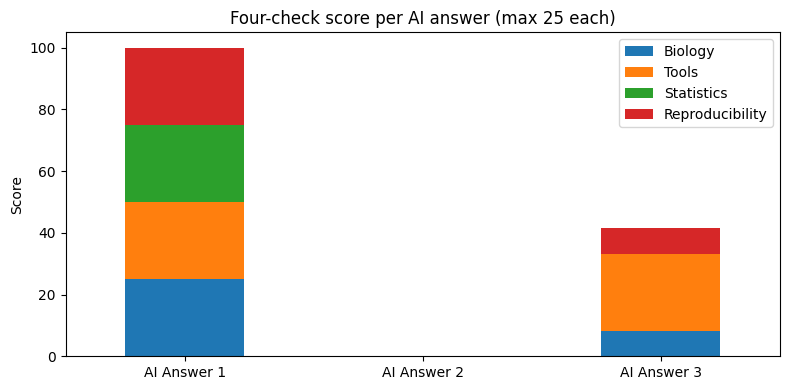

In [ ]:

# Cell 4: Judge 3 AI answers: biology, tools/parameters, statistics, reproducibility

REAL_TOOLS = {"fastqc","multiqc","fastp","STAR","salmon","featureCounts","samtools","hisat2",
              "bwa","gatk","nextflow","snakemake","docker","conda","git","Rscript","python",
              "mkdir","cd","zcat","gunzip","echo"}
VALID_FLAGS = {
    "STAR": {"--runThreadN","--genomeDir","--readFilesIn","--readFilesCommand","--outSAMtype",
             "--quantMode","--outFileNamePrefix"},
    "featureCounts": {"-a","-o","-T","-p","-s","-t","-g"},
    "fastp": {"-i","-I","-o","-O","-h","-j","-w","--detect_adapter_for_pe"},
    "samtools": {"sort","index","view","flagstat","-@","-o","-b","-F","-f"},
    "fastqc": {"-o","-t"},
}

ai_answers = {
"AI Answer 1": """Step 1: QC with FastQC, then trim adapters with fastp.
$ fastqc -o qc/ -t 4 S1_R1.fq.gz
$ fastp -i S1_R1.fq.gz -I S1_R2.fq.gz -o t1.fq.gz -O t2.fq.gz --detect_adapter_for_pe
Step 2: Align to the GRCh38 genome with STAR, using the GENCODE annotation.
$ STAR --runThreadN 8 --genomeDir idx/ --readFilesIn t1.fq.gz t2.fq.gz --readFilesCommand zcat --outSAMtype BAM SortedByCoordinate
Step 3: Count reads per gene.
$ featureCounts -a gencode.gtf -o counts.txt -T 8 -p aligned.bam
Step 4: Check PCA for batch effect. Use DESeq2 on raw counts with design ~ batch + condition. Use Benjamini-Hochberg FDR < 0.05 and |log2FC| > 1.
Step 5: Run in Nextflow with Docker, fixed tool versions, Git, and random seed 42.""",

"AI Answer 2": """I am 100% sure this new tool is the best way for everything.
$ RNAseqMagic --auto-align --fix-all reads.fq
$ STAR --runThreadN 8 --fastMode --autoBatchFix --genomeDir idx/
Convert the counts to TPM and run a t-test. Genes with p < 0.05 are significant.""",

"AI Answer 3": """Align reads with STAR to the human genome and count with featureCounts. I will definitely get the right answer, always.
$ STAR --runThreadN 8 --genomeDir idx/ --readFilesIn r1.fq.gz r2.fq.gz --outSAMtype BAM SortedByCoordinate
$ featureCounts -a genes.gtf -o counts.txt -T 8 aligned.bam
Compute FPKM and use a t-test, then report genes with p < 0.05. Save the code in Git.""",
}

def check_commands(text):
    problems = []
    for line in text.splitlines():
        line = line.strip()
        if not line.startswith("$ "):
            continue
        parts = line[2:].split()
        tool = parts[0]
        if tool not in REAL_TOOLS:
            problems.append(("tool", f"Unknown tool: {tool}"))
            continue
        if tool in VALID_FLAGS:
            for tok in parts[1:]:
                if tok.startswith("-") and tok not in VALID_FLAGS[tool]:
                    problems.append(("flag", f"Unknown flag for {tool}: {tok}"))
    return problems

def has(pattern, text):
    return re.search(pattern, text, re.I) is not None

# (category, check name, test function(prose, cmd_problems), simple fix)
CHECKS = [
    ("Biology", "Reference genome / annotation stated", lambda p, c: has(r"genome|gtf|annotation|grch|hg38", p),
     "State the reference genome and annotation version."),
    ("Biology", "QC step before analysis", lambda p, c: has(r"fastqc|multiqc|pca|quality", p),
     "Add QC (FastQC/MultiQC) and a PCA check."),
    ("Biology", "Batch effect considered", lambda p, c: has(r"batch", p),
     "Check PCA for batch and put batch in the model."),
    ("Tools", "No made-up tool", lambda p, c: not any(k == "tool" for k, _ in c),
     "Use only real, documented tools."),
    ("Tools", "No made-up flag", lambda p, c: not any(k == "flag" for k, _ in c),
     "Check every flag in the tool manual."),
    ("Statistics", "Multiple-testing correction (FDR)", lambda p, c: has(r"fdr|benjamini", p),
     "Use Benjamini-Hochberg FDR, not raw p-values."),
    ("Statistics", "No TPM/FPKM used for testing", lambda p, c: not has(r"tpm|fpkm", p),
     "Use raw counts with DESeq2/edgeR, not TPM/FPKM."),
    ("Statistics", "Proper DE model or effect-size cutoff", lambda p, c: has(r"deseq2|edger|limma|log2fc", p),
     "Use DESeq2/edgeR/limma and add a fold-change cutoff."),
    ("Reproducibility", "Random seed saved", lambda p, c: has(r"seed", p),
     "Save the random seed."),
    ("Reproducibility", "Tool versions fixed", lambda p, c: has(r"version", p),
     "Record fixed tool versions."),
    ("Reproducibility", "Workflow / container / Git used", lambda p, c: has(r"nextflow|snakemake|docker|conda|git", p),
     "Use Nextflow/Snakemake, containers, and Git."),
]
CATEGORIES = ["Biology", "Tools", "Statistics", "Reproducibility"]

def overconfident(text):
    return has(r"100%|definitely|always|guaranteed|perfect", text)

def verdict(total, hallucinated, overconf):
    if hallucinated:
        return "REJECT (made-up tool or flag)"
    if overconf and total < 70:
        return "REJECT (confident but wrong)"
    if total >= 80:
        return "ACCEPT"
    if total >= 50:
        return "NEEDS REVISION"
    return "REJECT"

review = {}
for name, text in ai_answers.items():
    prose = "\n".join(l for l in text.splitlines() if not l.strip().startswith("$ "))
    cmd_problems = check_commands(text)
    cat_scores = {c: 0.0 for c in CATEGORIES}
    failed = []
    for cat in CATEGORIES:
        cat_checks = [c for c in CHECKS if c[0] == cat]
        per = 25 / len(cat_checks)
        for _, check_name, test, fix in cat_checks:
            if test(prose, cmd_problems):
                cat_scores[cat] += per
            else:
                failed.append((cat, check_name, fix))
    total = round(sum(cat_scores.values()))
    review[name] = {"scores": {k: round(v, 1) for k, v in cat_scores.items()}, "total": total,
                    "failed": failed, "cmd_problems": cmd_problems,
                    "overconf": overconfident(text),
                    "verdict": verdict(total, len(cmd_problems) > 0, overconfident(text))}

print("=" * 64)
print("EXPERT REVIEW REPORT")
print("=" * 64)
for name, r in review.items():
    print(f"\n{name}  ->  {r['verdict']}   (total {r['total']}/100)")
    print("  Scores:", r["scores"])
    if r["overconf"]:
        print("  Warning: strong confidence words found (100% / definitely / always).")
    for _, msg in r["cmd_problems"]:
        print("  HALLUCINATION:", msg)
    for cat, chk, fix in r["failed"]:
        print(f"  - [{cat}] {chk}. Fix: {fix}")

score_df = pd.DataFrame({n: r["scores"] for n, r in review.items()}).T
score_df.plot(kind="bar", stacked=True, figsize=(8, 4), rot=0)
plt.title("Four-check score per AI answer (max 25 each)")
plt.ylabel("Score"); plt.tight_layout(); plt.show()

Cell 5 (Code): Retrieval to find evidence (the idea behind RAG)

In [ ]:

# Cell 5: Simple retrieval (TF-IDF) finds the best evidence note for each question or claim
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

knowledge_base = [
    "TPM and FPKM are within-sample units and should not be used for differential expression testing between groups. Use raw counts with DESeq2 or edgeR.",
    "Add batch to the model design as batch plus condition. Do not correct the data first and then test again.",
    "Benjamini-Hochberg FDR controls false discoveries when testing thousands of genes. Raw p-values give many false positives.",
    "Mark duplicates and use the same reference genome version in variant calling with GATK HaplotypeCaller.",
    "Single-cell QC removes cells with high mitochondrial percentage and doublets with very high gene counts.",
    "Reproducible pipelines use Nextflow or Snakemake, containers with fixed versions, Git, and saved random seeds.",
    "Feature selection must happen inside cross-validation, otherwise data leakage gives fake accuracy.",
    "STAR aligns RNA-seq reads to a genome and featureCounts counts reads per gene using a GTF annotation.",
]

# (claim or question, index of the correct evidence note)
claims = [
    ("Can I use FPKM values for a t-test between disease and healthy?", 0),
    ("Should I remove the batch effect first and then run the test again?", 1),
    ("Why do thousands of genes tested need FDR instead of raw p-values?", 2),
    ("Which reference genome version and duplicate step for GATK variant calling?", 3),
    ("Which cells should be removed for mitochondrial percentage or doublets in single-cell QC?", 4),
    ("How do I make a pipeline reproducible with seeds, containers and Git?", 5),
    ("Does selecting top features before cross-validation cause leakage and fake accuracy?", 6),
    ("Which tool counts reads per gene with a GTF after STAR alignment?", 7),
]

vec = TfidfVectorizer(stop_words="english")
kb_matrix = vec.fit_transform(knowledge_base)

rows, hits = [], 0
for text, gold in claims:
    sims = cosine_similarity(vec.transform([text]), kb_matrix)[0]
    top = int(np.argmax(sims))
    ok = (top == gold)
    hits += int(ok)
    rows.append({"claim": text[:55] + "...", "retrieved_note": top, "correct_note": gold,
                 "similarity": round(float(sims[top]), 2), "hit": ok})

retrieval_table = pd.DataFrame(rows)
print(retrieval_table.to_string(index=False))
hit_rate = hits / len(claims)
print(f"\nTop-1 retrieval hit rate: {hit_rate:.0%}")

# Example: use the evidence to support a review comment
text, gold = claims[0]
sims = cosine_similarity(vec.transform([text]), kb_matrix)[0]
print("\nExample evidence for the claim:")
print("  Claim   :", text)
print("  Evidence:", knowledge_base[int(np.argmax(sims))])
print("\nNote: this is basic keyword retrieval. Real RAG uses embeddings, but the idea is the same:")
print("find evidence first, then judge the answer against it.")

                                                     claim  retrieved_note  correct_note  similarity  hit
Can I use FPKM values for a t-test between disease and ...               0             0        0.23 True
Should I remove the batch effect first and then run the...               1             1        0.62 True
Why do thousands of genes tested need FDR instead of ra...               2             2        0.57 True
Which reference genome version and duplicate step for G...               3             3        0.79 True
Which cells should be removed for mitochondrial percent...               4             4        0.73 True
How do I make a pipeline reproducible with seeds, conta...               5             5        0.59 True
Does selecting top features before cross-validation cau...               6             6        0.68 True
Which tool counts reads per gene with a GTF after STAR ...               7             7        0.68 True

Top-1 retrieval hit rate: 100%

Example evide

Cell 6 (Code): Your honest AI experience card and final scorecard

In [ ]:

# Cell 6: Fill this card with REAL facts only. The interviewer may ask about every line.

FILL = "FILL_ME"

my_ai_projects = [
    {
        "project": "CRISPR gRNA on-target vs off-target model (CNN + LSTM)",
        "data": FILL,           # example: "simulated data" or "real public GUIDE-seq data"
        "model": "CNN + LSTM",
        "metric": FILL,         # example: "AUC 0.xx on a held-out test set"
        "my_role": FILL,        # example: "designed, coded, and tested it"
        "limitation": FILL,     # example: "no external validation set"
    },
    {
        "project": "Multi-omics biomarker pipeline (ElasticNet, Random Forest/XGBoost, SHAP)",
        "data": FILL,
        "model": "ElasticNet + RF/XGBoost",
        "metric": FILL,
        "my_role": FILL,
        "limitation": FILL,
    },
]

for card in my_ai_projects:
    print("-" * 60)
    for k, v in card.items():
        print(f"{k:>11}: {v}")
    missing = [k for k, v in card.items() if v == FILL]
    print("  STATUS:", "Ready to use" if not missing else "Fill these first: " + ", ".join(missing))

# ---------- Final scorecard ----------
best_answer = max(review, key=lambda n: review[n]["total"])
print("\n" + "=" * 64)
print("FINAL SCORECARD (interview answer -> proof from this lab)")
print("=" * 64)
print(f"1. Judge AI answers (4 checks)  -> best answer: {best_answer} ({review[best_answer]['total']}/100)")
print(f"2. Made-up tools/flags caught   -> {sum(len(r['cmd_problems']) for r in review.values())} problems found")
print(f"3. Confident but wrong flagged  -> {[n for n, r in review.items() if 'confident' in r['verdict']]}")
print(f"4. Good benchmark question      -> our question scored {quality_table.loc['Our question', 'quality_score']}/100, bad question {quality_table.loc['Bad question', 'quality_score']}/100")
print(f"5. Benchmark separates models   -> expert F1 {f1_ref} vs weak F1 {f1_weak}")
print(f"6. Retrieval for evidence       -> top-1 hit rate {hit_rate:.0%}")
print("7. AI experience                -> fill the card above with real facts")
print("\nEnvironment: python", platform.python_version(), "| numpy", np.__version__, "| pandas", pd.__version__, "| seed", SEED)
print("Note: the DE model here is a simple linear model for speed. Use DESeq2/edgeR on real counts.")

------------------------------------------------------------
    project: CRISPR gRNA on-target vs off-target model (CNN + LSTM)
       data: FILL_ME
      model: CNN + LSTM
     metric: FILL_ME
    my_role: FILL_ME
 limitation: FILL_ME
  STATUS: Fill these first: data, metric, my_role, limitation
------------------------------------------------------------
    project: Multi-omics biomarker pipeline (ElasticNet, Random Forest/XGBoost, SHAP)
       data: FILL_ME
      model: ElasticNet + RF/XGBoost
     metric: FILL_ME
    my_role: FILL_ME
 limitation: FILL_ME
  STATUS: Fill these first: data, metric, my_role, limitation

FINAL SCORECARD (interview answer -> proof from this lab)
1. Judge AI answers (4 checks)  -> best answer: AI Answer 1 (100/100)
2. Made-up tools/flags caught   -> 3 problems found
3. Confident but wrong flagged  -> ['AI Answer 3']
4. Good benchmark question      -> our question scored 100/100, bad question 0/100
5. Benchmark separates models   -> expert F1 0.872 vs we